In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
import pandas as pd

df = pd.read_csv("../data/raw/divorce.csv")

df.head()

,Sorry_end,Ignore_diff,begin_correct,Contact,Special_time,No_home_time,2_strangers,enjoy_holiday,enjoy_travel,common_goals,...,silence_for_harm,silence_fear_anger,I'm_right,accusations,I'm_not_guilty,I'm_not_wrong,no_hesitancy_inadequate,you're_inadequate,incompetence,Divorce_Y_N
0,2,2,4,1,0,0,0,0,0,0,...,2,1,3,3,3,2,3,2,1,1
1,4,4,4,4,4,0,0,4,4,4,...,2,2,3,4,4,4,4,2,2,1
2,2,2,2,2,1,3,2,1,1,2,...,3,2,3,1,1,1,2,2,2,1
3,3,2,3,2,3,3,3,3,3,3,...,2,2,3,3,3,3,2,2,2,1
4,2,2,1,1,1,1,0,0,0,0,...,2,1,2,3,2,2,2,1,0,1


### Visualiseringar

### 1. Klassfördelning
Visar hur många som tillhör respektive klass: 

In [19]:
print(df.columns[-1])

Divorce_Y_N


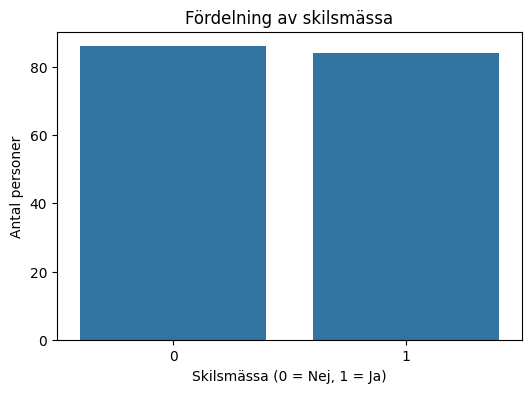

In [20]:
target = "Divorce_Y_N"

plt.figure(figsize=(6,4))
sns.countplot(x=df[target])

plt.title("Fördelning av skilsmässa")
plt.xlabel("Skilsmässa (0 = Nej, 1 = Ja)")
plt.ylabel("Antal personer")
plt.show()

### Klassfördelning för målvariabeln

Diagrammet visar fördelningen mellan observationer som tillhör klassen skilsmässa (1) och ingen skilsmässa (0).

Resultatet visar att datasetet är välbalanserat med ungefär lika många observationer i båda klasserna (86 respektive 84 observationer).

En balanserad klassfördelning minskar risken för att modellen gynnas av den vanligaste klassen och gör att utvärderingsmått som Accuracy, Precision, Recall och F1-score blir mer tillförlitliga.

Den jämna fördelningen förklarar även varför SMOTE inte förbättrade modellernas resultat i detta projekt.

### 2. Modelljämförelse (Accuracy)

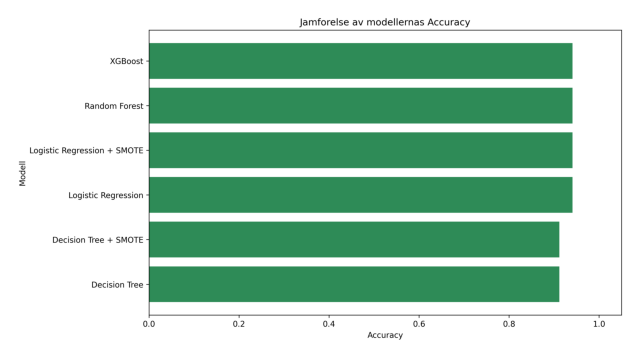

In [21]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("../reports/utvardering/accuracy_jamforelse.png")

plt.figure(figsize=(8,6))
plt.imshow(img)
plt.axis("off")
plt.show()

### Jämförelse av Accuracy mellan modeller

Diagrammet visar Accuracy för samtliga modeller som ingick i utvärderingen.

Logistic Regression, Random Forest och XGBoost uppnådde samtliga en Accuracy på 94,1 %, medan Decision Tree uppnådde 91,2 %.

Resultatet tyder på att flera olika modelltyper kan identifiera mönster i datan med hög träffsäkerhet.

Eftersom de mer avancerade modellerna inte gav bättre resultat än Logistic Regression finns det ingen tydlig prestandafördel med att välja en mer komplex modell.

### 3. Faktorer med starkast samband till skilsmässa

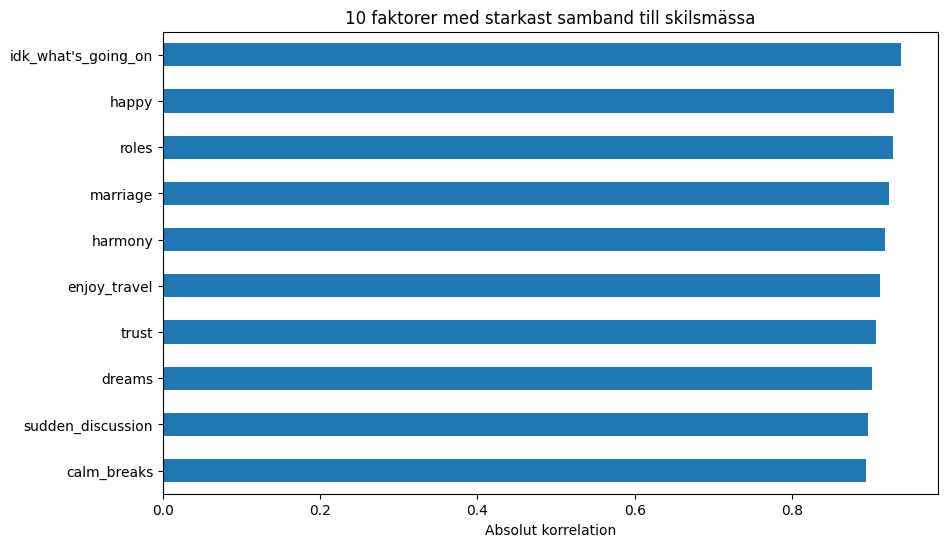

In [22]:
import matplotlib.pyplot as plt

target = "Divorce_Y_N"

corr = df.corr(numeric_only=True)[target]

corr = corr.drop(target)

corr = corr.abs().sort_values(ascending=False)

top10 = corr.head(10)

plt.figure(figsize=(10,6))
top10.sort_values().plot(kind="barh")

plt.xlabel("Absolut korrelation")
plt.title("10 faktorer med starkast samband till skilsmässa")

plt.show()

### Tolkning av faktorer med starkast samband till skilsmässa
Visualiseringen visar de tio variabler som hade starkast statistiskt samband med målvariabeln Divorce_Y_N.

Resultatet indikerar att faktorer som lycka i relationen (happy), harmoni (harmony), tillit (trust), upplevelsen av äktenskapet (marriage), gemensamma drömmar (dreams), resor och gemensamma aktiviteter (enjoy_travel) samt hantering av diskussioner och konflikter (sudden_discussion och calm_breaks) hade starkast koppling till om en relation klassificerades som stabil eller ledde till skilsmässa.

Generellt tyder resultaten på att relationens kvalitet, kommunikation, konflikthantering och upplevelsen av gemenskap är viktigare än enskilda demografiska faktorer.

Det är viktigt att notera att visualiseringen visar statistiska samband och inte bevisar orsakssamband. Faktorerna kan därför inte tolkas som direkta orsaker till skilsmässa, utan som variabler som i detta dataset är starkt förknippade med utfallet.

### 4. Skillnader mellan stabila relationer och skilsmässor

<Figure size 1200x600 with 0 Axes>

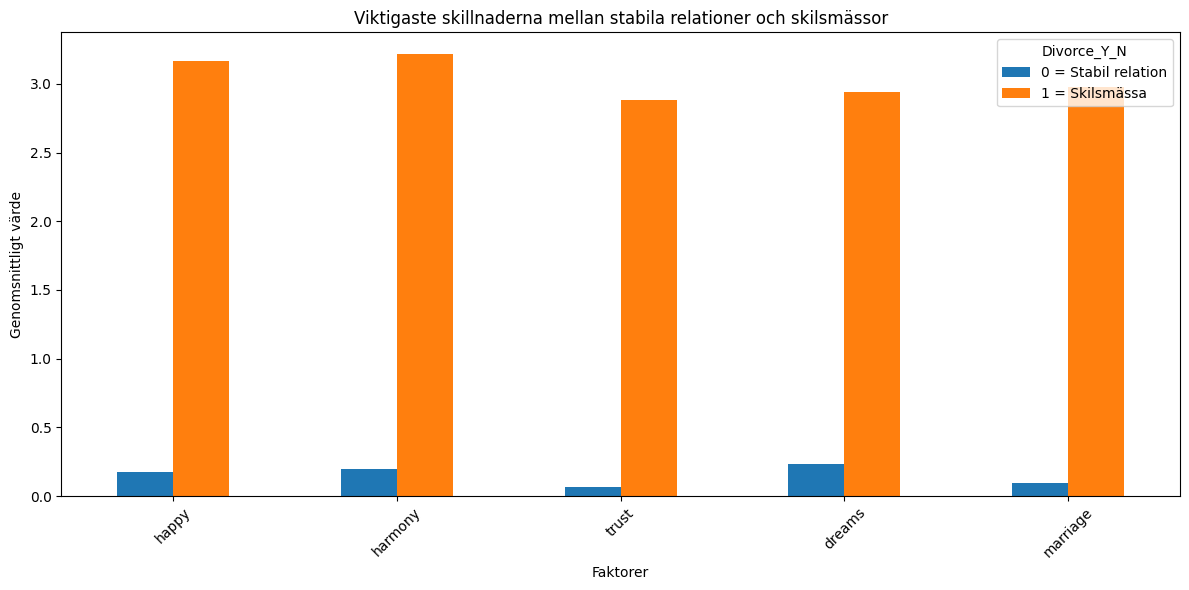

In [23]:
import matplotlib.pyplot as plt

features = [
    "happy",
    "harmony",
    "trust",
    "dreams",
    "marriage"
]

group_means = df.groupby("Divorce_Y_N")[features].mean()

plt.figure(figsize=(12,6))

group_means.T.plot(
    kind="bar",
    figsize=(12,6)
)

plt.title(
    "Viktigaste skillnaderna mellan stabila relationer och skilsmässor"
)

plt.xlabel("Faktorer")
plt.ylabel("Genomsnittligt värde")

plt.xticks(rotation=45)
plt.legend(
    title="Divorce_Y_N",
    labels=[
        "0 = Stabil relation",
        "1 = Skilsmässa"
    ]
)

plt.tight_layout()
plt.show()

### Skillnader mellan stabila relationer och skilsmässor
Denna visualisering jämför genomsnittliga värden för de fem faktorer som hade starkast samband med skilsmässa i datasetet.

Resultatet visar tydliga skillnader mellan relationer som förblev stabila (Divorce_Y_N = 0) och relationer som slutade i skilsmässa (Divorce_Y_N = 1).

De största skillnaderna observeras inom:

Lycka i relationen (happy)
Harmoni i relationen (harmony)
Tillit mellan parterna (trust)
Gemensamma drömmar och framtidsmål (dreams)
Synen på relationen och äktenskapet (marriage)
Visualiseringen indikerar att kvaliteten på relationen, graden av tillit samt parets upplevelse av gemenskap och framtidstro är starkt kopplade till utfallet i datasetet.

Det är viktigt att notera att visualiseringen visar statistiska samband och inte bevisar orsakssamband.

### 5. Relationsprofil (Heatmap)

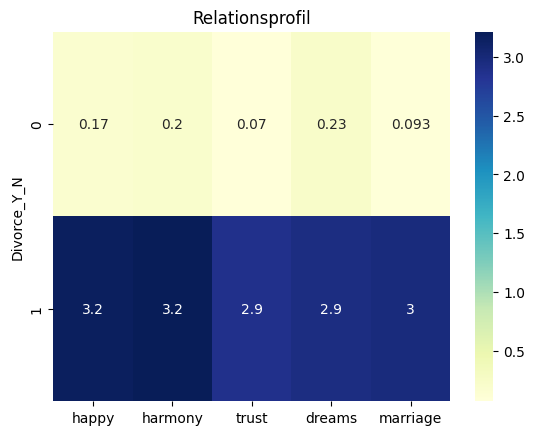

In [24]:
features = ["happy","harmony","trust","dreams","marriage"]

group_means = df.groupby("Divorce_Y_N")[features].mean()

sns.heatmap(
    group_means,
    annot=True,
    cmap="YlGnBu"
)

plt.title("Relationsprofil")
plt.show()

### Tolkning av relationsprofilen
Heatmapen visualiserar de genomsnittliga värdena för de fem faktorer som visade starkast samband med skilsmässa i datasetet.

Genom att jämföra grupperna blir det tydligt att relationer som slutade i skilsmässa skiljer sig markant från stabila relationer inom flera centrala områden.

De största skillnaderna återfinns inom:

Lycka i relationen (happy)
Harmoni i relationen (harmony)
Tillit mellan parterna (trust)
Gemensamma drömmar och framtidsmål (dreams)
Synen på äktenskapet och relationen (marriage)
Resultaten tyder på att långsiktigt stabila relationer kännetecknas av högre grad av tillit, harmoni, gemensam framtidstro och en mer positiv upplevelse av relationen.

Samtidigt verkar konflikter, minskad tillit och en svagare känsla av gemenskap vara vanligare i relationer som slutade i skilsmässa.

Visualiseringen ger därmed en övergripande profil av vad som skiljer långsiktigt lyckliga relationer från relationer som inte förblir stabila.

Det är viktigt att betona att resultaten visar statistiska samband i datasetet och inte kan användas för att fastställa direkta orsaker till skilsmässa.

### Både korrelationsanalysen och jämförelsen mellan grupperna pekar på samma mönster:

Harmoni
Tillit
Lycka
Gemensamma drömmar
Positiv syn på relationen
är de faktorer som tydligast skiljer stabila relationer från relationer som slutade i skilsmässa.

Dessa faktorer kan därför betraktas som de viktigaste framgångsfaktorerna för långsiktigt lyckliga relationer i det analyserade datasetet.

### 6. Korrelationsmatris för toppfaktorer

<Axes: >

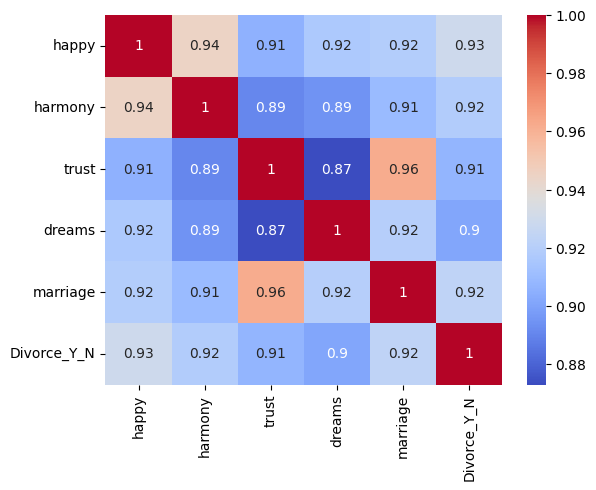

In [25]:
features = [
    "happy",
    "harmony",
    "trust",
    "dreams",
    "marriage",
    "Divorce_Y_N"
]

sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap="coolwarm"
)

### Tolkning av korrelationsmatris för toppfaktorer
Korrelationsmatrisen visar sambanden mellan de fem faktorer som identifierades som starkast kopplade till skilsmässa: lycka (happy), harmoni (harmony), tillit (trust), gemensamma drömmar (dreams) och synen på äktenskapet (marriage).

Resultaten visar mycket starka positiva samband mellan samtliga faktorer (korrelationer mellan cirka 0,87 och 0,96). Detta innebär att faktorerna ofta förekommer tillsammans.

Exempelvis tenderar relationer som kännetecknas av hög tillit även att uppvisa högre grad av harmoni, större upplevd lycka, fler gemensamma framtidsdrömmar och en mer positiv syn på relationen.

Samtliga fem faktorer uppvisar dessutom mycket starka samband med målvariabeln Divorce_Y_N (cirka 0,90–0,93), vilket visar att de är nära kopplade till om en relation klassificeras som stabil eller som skilsmässa.

Analysen tyder på att långsiktigt lyckliga relationer inte kännetecknas av en enskild faktor utan snarare av ett mönster där flera positiva relationsfaktorer samverkar samtidigt.

Det är viktigt att notera att korrelation inte innebär kausalitet. Visualiseringen visar statistiska samband i datamaterialet men kan inte användas för att fastställa direkta orsaker till skilsmässa.

### 7. SHAP Random Forest

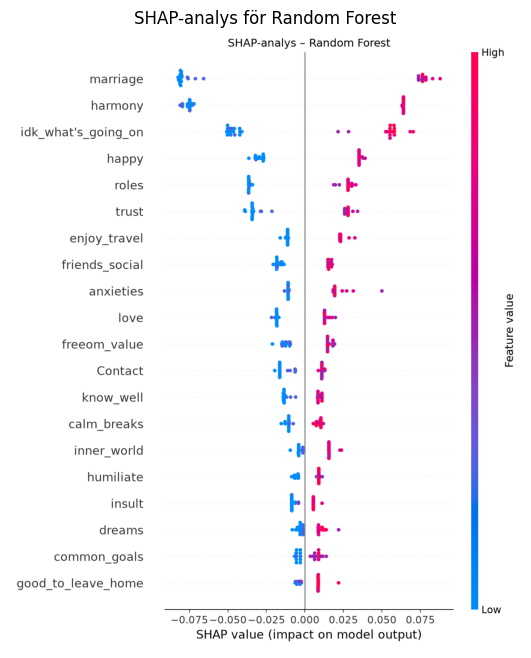

In [26]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("../reports/shap_random_forest.png")

plt.figure(figsize=(12,8))
plt.imshow(img)
plt.axis("off")

plt.title(
    "SHAP-analys för Random Forest"
)

plt.show()

### Tolkning av SHAP-analysen för Random Forest
SHAP-analysen används för att förklara hur Random Forest-modellen fattar sina beslut.

Visualiseringen visar vilka variabler som har störst påverkan på modellens prediktioner. Variabler som ligger högst i diagrammet bidrar mest till att modellen klassificerar en relation som stabil eller som skilsmässa.

Om flera av de faktorer som tidigare identifierats i korrelationsanalysen även återfinns bland de viktigaste SHAP-faktorerna stärker detta trovärdigheten i resultaten.

Analysen indikerar att modellens beslut i stor utsträckning baseras på relationella faktorer såsom tillit, harmoni, upplevd lycka, gemensamma mål och synen på relationen.

SHAP bidrar till ökad transparens genom att göra det möjligt att förstå vilka faktorer modellen använder vid sina prediktioner.

Det är viktigt att notera att SHAP beskriver modellens logik och inte bevisar att en faktor orsakar skilsmässa.

### 8. SHAP XGBoost


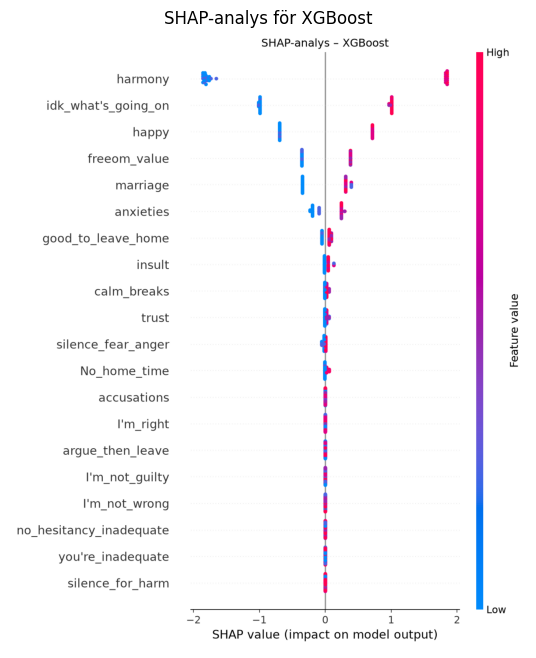

In [27]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("../reports/shap_xgboost.png")

plt.figure(figsize=(12,8))
plt.imshow(img)
plt.axis("off")

plt.title(
    "SHAP-analys för XGBoost"
)

plt.show()

### Tolkning av SHAP-analysen för XGBoost
SHAP-analysen visar vilka variabler som hade störst betydelse för XGBoost-modellens prediktioner.

Genom att jämföra resultaten från Random Forest och XGBoost kan vi undersöka om olika modeller identifierar samma viktiga faktorer.

Om samma variabler återkommer i båda modellerna stärker det slutsatsen att dessa faktorer har en stark koppling till relationens stabilitet i datasetet.

Resultaten tyder på att relationens kvalitet, tillit, harmoni, gemensamma framtidsmål och övergripande nöjdhet är centrala faktorer i modellernas bedömningar.

SHAP-analysen fungerar därför som ett viktigt komplement till korrelationsanalysen genom att visa vilka faktorer som faktiskt används av maskininlärningsmodellerna.

Precis som övriga analyser visar SHAP statistiska samband och modellbeteenden, men inte direkta orsakssamband.

### 9. Topp 10 framgångsfaktorer

<Axes: >

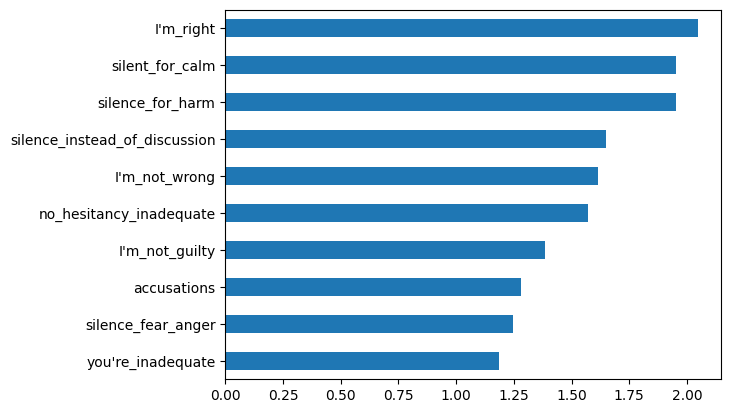

In [28]:
stable = df[df["Divorce_Y_N"] == 0]

top_success = stable.mean(
    numeric_only=True
).drop("Divorce_Y_N") \
 .sort_values(ascending=False) \
 .head(10)

top_success.sort_values().plot(
    kind="barh"
)

### Tolkning av topp 10 framgångsfaktorer
Visualiseringen visar de variabler som hade högst genomsnittliga värden bland relationer som inte slutade i skilsmässa (Divorce_Y_N = 0).

Flera av faktorerna handlar om konflikthantering, kommunikation och hur meningsskiljaktigheter hanteras inom relationen.

Resultaten indikerar att stabila relationer kännetecknas av ett mönster där konflikter hanteras på ett mer konstruktivt sätt och där parterna i större utsträckning undviker destruktiva kommunikationsmönster.

De mest framträdande faktorerna handlar om:

Hur oenighet uttrycks och hanteras
Hur skuld och ansvar fördelas
Hantering av kritik och anklagelser
Förmågan att skapa lugn i konfliktsituationer
Kommunikation vid meningsskiljaktigheter
Resultaten tyder på att långsiktigt stabila relationer inte enbart präglas av positiva känslor såsom lycka och harmoni, utan även av en fungerande konflikthantering och konstruktiv kommunikation.

Det är viktigt att notera att visualiseringen visar samband inom det analyserade datasetet och inte kan användas för att fastställa direkta orsaker till skilsmässa.

### 10. Topp 10 riskfaktorer

<Axes: >

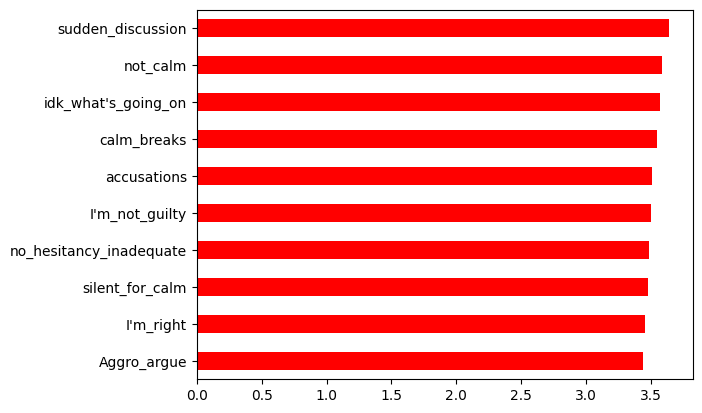

In [29]:
divorce = df[df["Divorce_Y_N"] == 1]

top_risk = divorce.mean(
    numeric_only=True
).drop("Divorce_Y_N") \
 .sort_values(ascending=False) \
 .head(10)

top_risk.sort_values().plot(
    kind="barh",
    color="red"
)

### Tolkning av topp 10 riskfaktorer

Visualiseringen visar de faktorer som hade högst genomsnittliga värden bland relationer som slutade i skilsmässa (Divorce_Y_N = 1).

Flera av de identifierade riskfaktorerna handlar om konflikthantering, kommunikationssvårigheter och negativa interaktionsmönster mellan parterna.

De mest framträdande faktorerna inkluderar:

- Plötsliga och eskalerande diskussioner (sudden_discussion)
- Svårigheter att behålla lugnet vid konflikter (not_calm)
- Osäkerhet kring vad som händer i relationen (idk_what's_going_on)
- Svårigheter att återgå till lugn efter konflikter (calm_breaks)
- Anklagelser mellan parterna (accusations)
- Aggressiva gräl (Aggro_argue)

Resultaten tyder på att relationsproblem ofta är kopplade till hur konflikter hanteras snarare än att konflikter i sig förekommer. Relationer som slutade i skilsmässa uppvisade i högre grad mönster av anklagelser, aggressiva argument och bristande kommunikation.

Visualiseringen indikerar även att återkommande negativa kommunikationsmönster kan vara viktiga indikatorer på relationsinstabilitet.

Det är viktigt att notera att resultaten visar statistiska samband i datasetet och inte bevisar att dessa faktorer orsakar skilsmässa.

### Slutlig slutsats
Projektet visade att skilsmässa kan förutsägas med hög träffsäkerhet baserat på enkätsvar om relationens kvalitet, kommunikation och konflikthantering.

De bäst presterande modellerna (Logistic Regression, Random Forest och XGBoost) uppnådde cirka 94 % accuracy och identifierade korrekt majoriteten av relationerna i testdatan.

Analysen visade att de starkaste framgångsfaktorerna för långsiktigt stabila relationer var:

Lycka i relationen
Harmoni
Tillit
Gemensamma framtidsdrömmar
En positiv syn på relationen och äktenskapet
Samtidigt var de tydligaste riskfaktorerna:

Aggressiva argument
Anklagelser
Bristande kommunikation
Svårigheter att hantera konflikter
Plötsliga och eskalerande diskussioner

Sammantaget tyder resultaten på att långsiktigt lyckliga relationer kännetecknas av både starka positiva relationsegenskaper och en konstruktiv hantering av konflikter.

### Slutlig slutsats
Resultaten visar att skilsmässa kan predikteras med hög noggrannhet, där de bästa modellerna uppnådde cirka 94 % accuracy. 

Analysen visar samtidigt att relationskvalitet är den starkaste förklaringsfaktorn bakom modellernas prediktioner. 
Faktorer såsom harmoni, lycka, tillit, kärlek, gemensamma mål och framtidsdrömmar återkommer konsekvent som kännetecken för stabila relationer. 

På motsvarande sätt präglas relationer med hög skilsmässorisk av aggressiva konflikter, anklagelser, bristande kommunikation och svårigheter att hantera meningsskiljaktigheter. 

Att liknande mönster identifierades genom korrelationsanalyser, gruppjämförelser och SHAP-baserad modelltolkning stärker resultatens trovärdighet.